# Objectifs d'apprentissage – Semaine 5

À l'issue de cette semaine, l'étudiant sera capable de :

- **Définir** la transformée en Z bilatérale d'une séquence.
- **Déterminer** la région de convergence (ROC) pour différentes séquences (causales, anticausales, bilatérales).
- **Calculer** la transformée en Z de séquences usuelles (impulsion, échelon, exponentielle, sinusoïde).
- **Déduire** une fonction de transfert $H(z)$ à partir d'une équation aux différences (méthode pas-à-pas).
- **Représenter** les pôles et zéros d'une fonction rationnelle.
- **Analyser** la stabilité d'un système LTI à partir de la position des pôles par rapport au cercle unité.
- **Utiliser** Python (numpy, scipy.signal, matplotlib) pour calculer et visualiser les pôles et zéros.
- **Appliquer** la transformée en Z à la résolution d'équations aux différences.
- **Concevoir** un filtre numérique concret (DC blocker) et le tester sur un **vrai fichier audio**.
- **Justifier** l'intérêt de la transformée en Z par rapport à l'analyse temporelle directe.

# 0. Glossaire des acronymes utilisés

| Acronyme | Signification (anglais) | Signification (français) |
|---|---|---|
| **DSP** | Digital Signal Processing | Traitement Numérique du Signal |
| **LTI** | Linear Time-Invariant | Linéaire et Invariant dans le Temps |
| **ROC** | Region Of Convergence | Région de Convergence |
| **BIBO** | Bounded-Input Bounded-Output | Entrée Bornée / Sortie Bornée |
| **FIR** | Finite Impulse Response | Réponse Impulsionnelle Finie |
| **IIR** | Infinite Impulse Response | Réponse Impulsionnelle Infinie |
| **TZ** | Z-Transform | Transformée en Z |
| **TF** | Transfer Function | Fonction de Transfert |
| **TFTD** | Discrete-Time Fourier Transform | Transformée de Fourier à Temps Discret (DTFT) |
| **FFT** | Fast Fourier Transform | Transformée de Fourier Rapide |
| **TF2ZPK** | Transfer Function → Zero-Pole-Gain | Conversion coefficients → pôles/zéros/gain |
| **DC** | Direct Current | Composante continue (fréquence nulle) |
| **ADC** | Analog-to-Digital Converter | Convertisseur Analogique-Numérique |
| **DAW** | Digital Audio Workstation | Station Audio Numérique (Ableton, Pro Tools…) |
| **ECG** | Electrocardiogram | Électrocardiogramme |
| **SNR** | Signal-to-Noise Ratio | Rapport Signal / Bruit |
| **EQM** | — | Erreur Quadratique Moyenne (MSE en anglais) |
| **WAV** | Waveform Audio File Format | Format de fichier audio PCM |

> **Convention** : dans ce notebook, on note $x[n]$ un signal à temps discret, $X(z)$ sa transformée en Z, $h[n]$ une réponse impulsionnelle, $H(z)$ la fonction de transfert associée.

# 1. Pourquoi la transformée en Z ? À quoi sert-elle ?

## 1.1 Le problème posé

En traitement du signal à temps discret, on manipule des **équations aux différences** du type :
$$ y[n] = a_1 y[n-1] + a_2 y[n-2] + b_0 x[n] + b_1 x[n-1] $$

Résoudre ces équations directement dans le **domaine temporel** (par récurrence) est possible mais **pénible** dès que l'ordre augmente. On ne voit pas facilement :
- si le système est **stable** ;
- comment il **filtre** les fréquences ;
- comment il réagit à un signal périodique ou sinusoïdal.

## 1.2 L'idée : passer dans un autre « monde »

La transformée en Z est l'**analogue discret** de la transformée de Laplace (utilisée pour les systèmes continus). Elle joue exactement le même rôle :

| Domaine temporel | Domaine $z$ |
|---|---|
| Convolution $y = x * h$ | **Multiplication** $Y(z) = X(z)\,H(z)$ |
| Équation aux différences | **Équation algébrique** rationnelle |
| Stabilité : $\sum_n \|h[n]\| < \infty$ | Pôles **strictement** dans le cercle unité |
| Réponse fréquentielle $H(e^{j\omega})$ | Évaluation $H(z)$ sur $\|z\|=1$ |
| Cascade de filtres $h_1 * h_2$ | Produit $H_1(z) \cdot H_2(z)$ |
| Récurrence (boucle) | Division de polynômes |

## 1.3 Analogie pédagogique

> Pensez à la transformée en Z comme à un **traducteur** : dans le monde temporel, une opération compliquée (convolution, récurrence) est **difficile** ; une fois traduite en « langue Z », la même opération devient une **simple multiplication ou division**. Il suffit de **retraduire** (transformée inverse) pour revenir au signal.

## 1.4 Applications concrètes

1. **Conception de filtres numériques** (audio, ECG, radar, télécom).
2. **Analyse de stabilité** des systèmes asservis discrets (robotique, contrôle).
3. **Compression et codage** (MP3, JPEG utilisent des transformées cousines).
4. **Communications numériques** : égalisation de canaux, détection.
5. **Nettoyage audio** : suppression du DC, réjecteur 50/60 Hz (voir sections 7 et 8).

## 1.5 Limites et alternatives

- La transformée en Z est **bien adaptée aux signaux échantillonnés**. Pour les signaux continus, on utilise **Laplace**.
- Pour une analyse purement **fréquentielle**, on utilise la **TFTD** (évaluation sur le cercle unité, $z = e^{j\omega}$).
- Pour un **calcul numérique rapide**, on utilise la **TFR** (FFT) — qui est la version discrète et finie de la TFTD.

---

# 2. Rappels théoriques

## 2.1 Définition de la transformée en Z
La transformée en Z **bilatérale** d'une séquence $x[n]$ est définie par :
$$ X(z) = \sum_{n=-\infty}^{\infty} x[n] z^{-n}, \qquad z \in \mathbb{C} $$
où $z$ est une variable complexe.

**Version unilatérale** (utilisée pour les systèmes causaux) :
$$ X(z) = \sum_{n=0}^{\infty} x[n] z^{-n} $$

## 2.2 Région de convergence (ROC)
La ROC est l'ensemble des valeurs de $z$ pour lesquelles la série converge. Elle dépend de la nature de la séquence :
- **Séquence causale** ($x[n]=0$ pour $n<0$) : ROC est l'extérieur d'un cercle, $|z| > r$.
- **Séquence anticausale** ($x[n]=0$ pour $n>0$) : ROC est l'intérieur d'un cercle, $|z| < r$.
- **Séquence bilatérale** : ROC est un anneau $r_1 < |z| < r_2$.

**Propriétés clés de la ROC** :
1. Elle ne contient **aucun pôle**.
2. Si $x[n]$ est de durée finie, ROC = plan complexe entier (sauf éventuellement $z=0$ et/ou $z=\infty$).
3. Si $x[n]$ est causale, ROC est l'extérieur d'un cercle passant par le pôle de plus grand module.
4. Si $x[n]$ est anticausale, ROC est l'intérieur d'un cercle passant par le pôle de plus petit module.

## 2.3 Pôles et zéros
Si $X(z)$ est une fonction rationnelle :
$$ X(z) = \frac{N(z)}{D(z)} = K \frac{\prod_k (z - z_k)}{\prod_i (z - p_i)} $$
- Les **zéros** $z_k$ sont les racines de $N(z)$ → $X(z_k) = 0$.
- Les **pôles** $p_i$ sont les racines de $D(z)$ → $X(p_i) \to \infty$.
- Le **gain** $K$ est un facteur scalaire.

## 2.4 Stabilité BIBO
Un système LTI est **stable** (BIBO) si et seulement si sa ROC contient le **cercle unité** ($|z|=1$).

Pour un système **causal**, cela équivaut à avoir tous les pôles **strictement à l'intérieur** du cercle unité ($|p_i| < 1$).

| Position des pôles | Stabilité (système causal) |
|---|---|
| Tous $\|p_i\| < 1$ | **Stable** |
| Un ou plusieurs $\|p_i\| = 1$ (simples) | **Marginalement stable** |
| Un ou plusieurs $\|p_i\| > 1$ | **Instable** |

## 2.5 Transformées usuelles (à retenir)

| Séquence $x[n]$ | Transformée $X(z)$ | ROC |
|---|---|---|
| $\delta[n]$ | $1$ | tout $z$ |
| $\delta[n-k]$ | $z^{-k}$ | $z \neq 0$ |
| $u[n]$ | $\dfrac{1}{1 - z^{-1}}$ | $\|z\| > 1$ |
| $a^n u[n]$ | $\dfrac{1}{1 - a z^{-1}}$ | $\|z\| > \|a\|$ |
| $-a^n u[-n-1]$ | $\dfrac{1}{1 - a z^{-1}}$ | $\|z\| < \|a\|$ |
| $n a^n u[n]$ | $\dfrac{a z^{-1}}{(1 - a z^{-1})^2}$ | $\|z\| > \|a\|$ |
| $\cos(\omega_0 n) u[n]$ | $\dfrac{1 - \cos(\omega_0) z^{-1}}{1 - 2\cos(\omega_0)z^{-1} + z^{-2}}$ | $\|z\| > 1$ |
| $\sin(\omega_0 n) u[n]$ | $\dfrac{\sin(\omega_0) z^{-1}}{1 - 2\cos(\omega_0)z^{-1} + z^{-2}}$ | $\|z\| > 1$ |

## 2.6 Propriétés utiles

| Propriété | Domaine temporel | Domaine $z$ |
|---|---|---|
| Linéarité | $a x_1[n] + b x_2[n]$ | $a X_1(z) + b X_2(z)$ |
| Décalage temporel | $x[n-k]$ | $z^{-k} X(z)$ |
| Convolution | $x[n] * h[n]$ | $X(z)\, H(z)$ |
| Multiplication par $n$ | $n\, x[n]$ | $-z \dfrac{dX(z)}{dz}$ |
| Théorème de la valeur initiale | $x[0]$ | $\lim_{z\to\infty} X(z)$ (causal) |
| Théorème de la valeur finale | $x[\infty]$ | $\lim_{z\to 1} (1-z^{-1})X(z)$ |

---

## 2.7 Méthode pas-à-pas : de l'équation aux différences à $H(z)$

### Procédure en 6 étapes

**Énoncé** : soit l'équation aux différences d'un système LTI causal (conditions initiales nulles) :
$$\sum_{k=0}^{N} a_k\, y[n-k] \;=\; \sum_{m=0}^{M} b_m\, x[n-m]$$

| Étape | Action | Résultat |
|---|---|---|
| **1** | Regrouper $y$ à gauche, $x$ à droite | Forme canonique |
| **2** | Appliquer $\mathcal{Z}$ terme à terme | Équation algébrique |
| **3** | Utiliser $y[n-k] \to z^{-k}Y(z)$ et $x[n-m] \to z^{-m}X(z)$ | $A(z)Y(z) = B(z)X(z)$ |
| **4** | Isoler le rapport $Y/X$ | $H(z) = B(z)/A(z)$ |
| **5** | Multiplier par $z^{\max(N,M)}$ | Forme polynomiale en $z$ |
| **6** | Résoudre $B(z)=0$ et $A(z)=0$ | Zéros et pôles |

### Propriétés utilisées

| Propriété | Domaine temporel | Domaine $z$ |
|---|---|---|
| **Linéarité** | $a\,x_1[n] + b\,x_2[n]$ | $a\,X_1(z) + b\,X_2(z)$ |
| **Décalage temporel** | $x[n-k]$ | $z^{-k}\,X(z)$ |

> ⚠️ **Hypothèse implicite** : le système est **causal** et les **conditions initiales sont nulles** ($y[-1]=y[-2]=\dots=0$). C'est la convention standard pour la transformée en Z **unilatérale**.

### Résultat général (à retenir)

$$ \boxed{H(z) \;=\; \frac{Y(z)}{X(z)} \;=\; \frac{\sum_{m=0}^{M} b_m\, z^{-m}}{\sum_{k=0}^{N} a_k\, z^{-k}} \;=\; \frac{B(z)}{A(z)}} $$

- $B(z)$ = polynôme du **numérateur** → donne les **zéros**.
- $A(z)$ = polynôme du **dénominateur** → donne les **pôles**.

### Exemple entièrement détaillé

**Équation** : $y[n] - 0{,}6\,y[n-1] + 0{,}08\,y[n-2] = x[n] - 0{,}2\,x[n-1]$

**Étape 2 et 3 — Transformée en Z** :
$$
\begin{aligned}
\mathcal{Z}\{y[n]\} &= Y(z) \\
\mathcal{Z}\{y[n-1]\} &= z^{-1}Y(z) \\
\mathcal{Z}\{y[n-2]\} &= z^{-2}Y(z) \\
\mathcal{Z}\{x[n]\} &= X(z) \\
\mathcal{Z}\{x[n-1]\} &= z^{-1}X(z)
\end{aligned}
$$

Ce qui donne :
$$Y(z) - 0{,}6\,z^{-1}Y(z) + 0{,}08\,z^{-2}Y(z) = X(z) - 0{,}2\,z^{-1}X(z)$$

**Étape 4 — Factorisation** :
$$(1 - 0{,}6\,z^{-1} + 0{,}08\,z^{-2})\,Y(z) = (1 - 0{,}2\,z^{-1})\,X(z)$$

**Étape 5 — Fonction de transfert** :
$$H(z) = \frac{Y(z)}{X(z)} = \frac{1 - 0{,}2\,z^{-1}}{1 - 0{,}6\,z^{-1} + 0{,}08\,z^{-2}}$$

**Étape 6 — Pôles et zéros** :

*Zéros* : $1 - 0{,}2\,z^{-1} = 0 \Rightarrow z_0 = 0{,}2$

*Pôles* : $z^2 - 0{,}6\,z + 0{,}08 = 0 \Rightarrow \Delta = 0{,}04 \Rightarrow p_{1,2} = \{0{,}4; 0{,}2\}$

**Simplification** : le zéro et le pôle en $0{,}2$ s'annulent → $H(z) = \dfrac{1}{1 - 0{,}4\,z^{-1}}$, **stable**, $h[n] = (0{,}4)^n u[n]$.

### Cas particuliers remarquables

| Équation aux différences | Fonction de transfert | Pôles | Stabilité |
|---|---|---|---|
| $y[n] = a\,y[n-1] + b\,x[n]$ | $\dfrac{b}{1 - a\,z^{-1}}$ | $a$ | $\|a\| < 1$ |
| $y[n] - a\,y[n-1] = x[n] - b\,x[n-1]$ | $\dfrac{1 - b\,z^{-1}}{1 - a\,z^{-1}}$ | $a$ | $\|a\| < 1$ |
| $\sum a_k y[n-k] = \sum b_m x[n-m]$ | $\dfrac{\sum b_m z^{-m}}{\sum a_k z^{-k}}$ | racines de $A(z)$ | tous $\|p_i\| < 1$ |

### Vérification croisée avec Python

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Exemple : y[n] - 0.6 y[n-1] + 0.08 y[n-2] = x[n] - 0.2 x[n-1]
b = [1, -0.2]         # numérateur : 1 - 0.2 z^-1
a = [1, -0.6, 0.08]   # dénominateur : 1 - 0.6 z^-1 + 0.08 z^-2

# Extraction des pôles et zéros
zeros, poles, gain = signal.tf2zpk(b, a)
print("Zéros :", zeros)
print("Pôles :", poles)
print("\nAnnulation pôle-zéro en 0.2 ?", np.isclose(zeros[0], poles[1]))

# Réponse impulsionnelle numérique
N = 10
imp = np.zeros(N); imp[0] = 1
h_num = signal.lfilter(b, a, imp)
n = np.arange(N)
h_theo = 0.4**n

print("\nh[n] numérique :", np.round(h_num, 6))
print("h[n] analytique:", np.round(h_theo, 6))
print(f"Erreur max : {np.max(np.abs(h_num - h_theo)):.2e}")
print("\n→ Confirme que H(z) = 1 / (1 - 0.4 z^-1) après simplification pôle-zéro")

Zéros : [0.2]
Pôles : [0.4 0.2]

Annulation pôle-zéro en 0.2 ? True

h[n] numérique : [1.000e+00 4.000e-01 1.600e-01 6.400e-02 2.560e-02 1.024e-02 4.096e-03
 1.638e-03 6.550e-04 2.620e-04]
h[n] analytique: [1.000e+00 4.000e-01 1.600e-01 6.400e-02 2.560e-02 1.024e-02 4.096e-03
 1.638e-03 6.550e-04 2.620e-04]
Erreur max : 5.55e-17

→ Confirme que H(z) = 1 / (1 - 0.4 z^-1) après simplification pôle-zéro


## Interprétation — Méthode pas-à-pas $H(z)$

> Chaque terme de décalage temporel dans l'équation aux différences se traduit par une **multiplication par $z^{-1}$** dans le domaine $z$. La fonction de transfert $H(z)$ n'est rien d'autre qu'une reformulation algébrique de l'équation aux différences : au lieu d'une récurrence, on résout une **équation rationnelle**.

**Où cette méthode est utilisée en pratique** :
- **Conception de filtres RIF** : $H(z) = \sum_k b_k z^{-k}$ (pas de dénominateur).
- **Filtres IIR** : $H(z) = \dfrac{\sum b_m z^{-m}}{\sum a_k z^{-k}}$ (récurrence).
- **Implémentation temps réel** : `scipy.signal.lfilter(b, a, x)` applique directement l'équation aux différences.

# 3. Démonstrations Python

## 3.1 Transformée en Z de séquences usuelles

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Import optionnel de sympy (calcul symbolique)
try:
    import sympy as sp
    SYMPY_AVAILABLE = True
    sp.init_printing()
    print("Bibliothèques chargées (sympy disponible).")
except ImportError:
    SYMPY_AVAILABLE = False
    print("Bibliothèques chargées (sympy NON disponible — mode numérique uniquement).")
    print("Pour l'installer : pip install sympy")

Bibliothèques chargées (sympy NON disponible — mode numérique uniquement).
Pour l'installer : pip install sympy


In [3]:
if SYMPY_AVAILABLE:
    z = sp.Symbol('z', complex=True)
    n = sp.Symbol('n', integer=True)
    a = sp.Symbol('a', real=True)

    # 1. Impulsion
    x1 = sp.KroneckerDelta(n, 0)
    X1 = sp.summation(x1 * z**(-n), (n, -sp.oo, sp.oo))
    print("1) Transformée de δ[n] :", X1)

    # 2. Échelon causal
    X2 = sp.summation(z**(-n), (n, 0, sp.oo))
    print("2) Transformée de u[n] :", sp.simplify(X2))

    # 3. Exponentielle causale
    X3 = sp.summation((a*z**(-1))**n, (n, 0, sp.oo))
    print("3) Transformée de a^n u[n] :", sp.simplify(X3))
else:
    print("Résultats théoriques :")
    print("1) δ[n]      → X(z) = 1                     ROC : tout z")
    print("2) u[n]      → X(z) = 1 / (1 - z^-1)         ROC : |z| > 1")
    print("3) a^n u[n]  → X(z) = 1 / (1 - a z^-1)       ROC : |z| > |a|")

Résultats théoriques :
1) δ[n]      → X(z) = 1                     ROC : tout z
2) u[n]      → X(z) = 1 / (1 - z^-1)         ROC : |z| > 1
3) a^n u[n]  → X(z) = 1 / (1 - a z^-1)       ROC : |z| > |a|


## Interprétation — Transformées usuelles

- **δ[n]** → $X(z) = 1$ : élément neutre.
- **u[n]** → pôle en $z=1$ **sur** le cercle unité → marginalement stable.
- **$a^n u[n]$** → pôle en $z = a$, ROC $|z| > |a|$.

**Règle clé** : pour une séquence causale, la ROC est l'**extérieur** du cercle de rayon égal au plus grand module de pôle.

## 3.2 Tracé des pôles et zéros

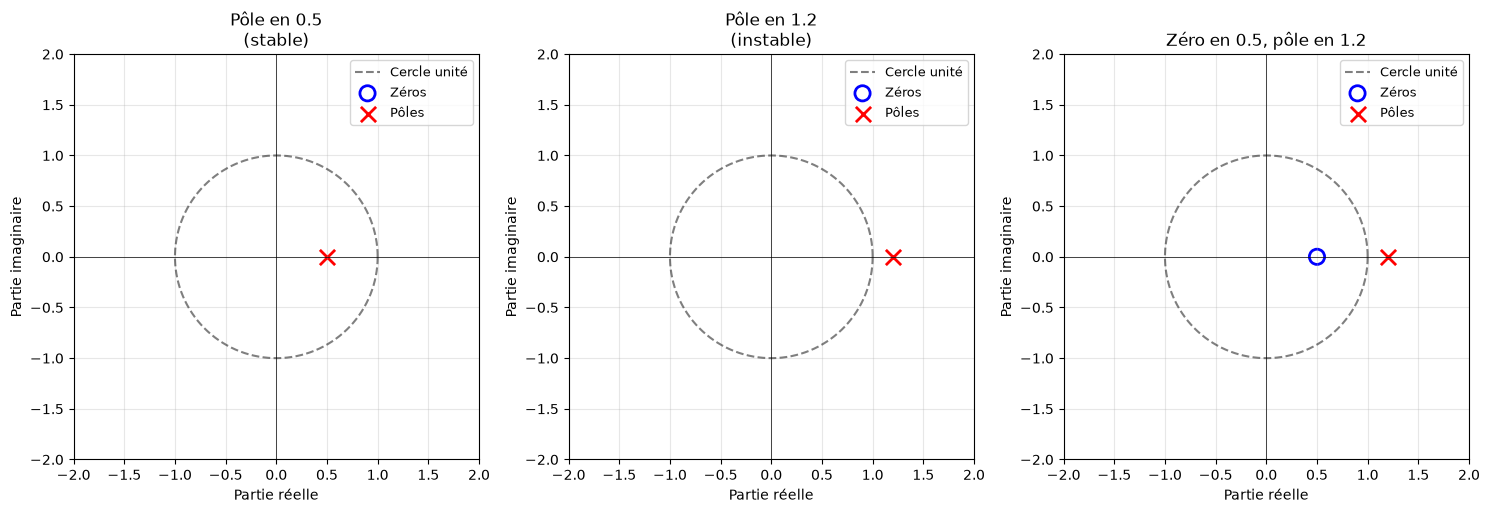

In [4]:
def plot_pole_zero(b, a, title='Diagramme pôles-zéros', ax=None):
    """Trace le diagramme pôles-zéros à partir de b (numérateur) et a (dénominateur)."""
    zeros, poles, gain = signal.tf2zpk(b, a)
    
    if ax is None:
        ax = plt.gca()
    
    theta = np.linspace(0, 2*np.pi, 400)
    ax.plot(np.cos(theta), np.sin(theta), 'k--', alpha=0.5, label='Cercle unité')
    ax.scatter(np.real(zeros), np.imag(zeros), marker='o', s=120,
               facecolors='none', edgecolors='b', linewidths=2, label='Zéros')
    ax.scatter(np.real(poles), np.imag(poles), marker='x', s=120,
               color='r', linewidths=2, label='Pôles')
    
    ax.axhline(0, color='black', linewidth=0.5)
    ax.axvline(0, color='black', linewidth=0.5)
    ax.grid(True, alpha=0.3)
    ax.set_aspect('equal')
    ax.set_xlim([-2, 2])
    ax.set_ylim([-2, 2])
    ax.set_xlabel('Partie réelle')
    ax.set_ylabel('Partie imaginaire')
    ax.set_title(title)
    ax.legend(loc='upper right', fontsize=9)
    
    return zeros, poles

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
plot_pole_zero([1], [1, -0.5], 'Pôle en 0.5\n(stable)', ax=axes[0])
plot_pole_zero([1], [1, -1.2], 'Pôle en 1.2\n(instable)', ax=axes[1])
plot_pole_zero([1, -0.5], [1, -1.2], 'Zéro en 0.5, pôle en 1.2', ax=axes[2])

plt.tight_layout()
plt.show()

## Interprétation — Diagramme pôles-zéros

- **Pôle à $z=0{,}5$** (|pôle| < 1) : système causal **stable**.
- **Pôle à $z=1{,}2$** (|pôle| > 1) : système causal **instable**.
- **Zéro + pôle** : le zéro ne compense pas un pôle instable s'il n'est pas au même endroit.

**Lecture géométrique** :
- Pôle **proche** du cercle → résonance.
- Zéro **proche** du cercle → atténuation.
- Zéro **sur** le cercle → atténuation infinie à cette fréquence (voir §7 et §8).

## 3.3 Stabilité et ROC

In [5]:
def check_stability(b, a, label=''):
    zeros, poles, gain = signal.tf2zpk(b, a)
    modules = np.abs(poles)
    
    if np.all(modules < 1):
        verdict = 'STABLE'
    elif np.any(modules > 1):
        verdict = 'INSTABLE'
    else:
        verdict = 'MARGINALEMENT STABLE (pôle sur le cercle)'
    
    print(f"--- {label} ---")
    print(f"  Pôles   : {np.round(poles, 4)}")
    print(f"  |pôles| : {np.round(modules, 4)}")
    print(f"  Verdict : {verdict}\n")
    return verdict

check_stability([1], [1, -0.5],       'Pôle 0.5')
check_stability([1], [1, -1.2],       'Pôle 1.2')
check_stability([1], [1, -1.0],       'Pôle 1.0 (sur le cercle)')
check_stability([1], [1, -0.5, 0.25], 'Deux pôles complexes conjugués')

--- Pôle 0.5 ---
  Pôles   : [0.5]
  |pôles| : [0.5]
  Verdict : STABLE

--- Pôle 1.2 ---
  Pôles   : [1.2]
  |pôles| : [1.2]
  Verdict : INSTABLE

--- Pôle 1.0 (sur le cercle) ---
  Pôles   : [1.]
  |pôles| : [1.]
  Verdict : MARGINALEMENT STABLE (pôle sur le cercle)

--- Deux pôles complexes conjugués ---
  Pôles   : [0.25+0.433j 0.25-0.433j]
  |pôles| : [0.5 0.5]
  Verdict : STABLE



'STABLE'

## Interprétation — Critère de stabilité

- **Pôle $0{,}5$** : stable.
- **Pôle $1{,}2$** : instable.
- **Pôle $1{,}0$** : marginalement stable (borné sans décroître).
- **Pôles complexes** de module $0{,}5$ : stable, réponse oscillante amortie.

**Pourquoi ce critère est puissant** : un simple calcul de racines de polynôme évite d'avoir à calculer une somme infinie $\sum |h[n]|$.

# 4. Exercices – Semaine 5

## Exercice 1 – Transformée en Z et ROC

Déterminer la transformée en Z et la ROC pour les séquences suivantes :

1. $x[n] = (0.5)^n u[n]$
2. $x[n] = - (0.5)^n u[-n-1]$
3. $x[n] = (0.5)^n u[n] + (2)^n u[-n-1]$
4. $x[n] = \delta[n] + \delta[n-1]$

### Correction détaillée

**1.** Séquence causale : $X(z) = \dfrac{1}{1 - 0{,}5 z^{-1}}$, ROC : $|z| > 0{,}5$.

**2.** Séquence anticausale : **même expression**, ROC : $|z| < 0{,}5$.

> **Insight** : la même expression rationnelle correspond à deux séquences différentes selon la ROC.

**3.** Bilatérale : ROC = anneau $0{,}5 < |z| < 2$.

**4.** Séquence finie : $X(z) = 1 + z^{-1}$, ROC : $z \neq 0$.

In [6]:
# Vérification numérique : reconstruire X(z) évalué sur le cercle unité
N = 100
n = np.arange(N)
x1 = 0.5**n

omega = np.linspace(-np.pi, np.pi, 500)
z_eval = np.exp(1j*omega)
X1_direct = np.array([np.sum(x1 * z**(-n)) for z in z_eval])
X1_formula = 1 / (1 - 0.5 * z_eval**(-1))

erreur = np.max(np.abs(X1_direct - X1_formula))
print(f"Erreur max série (N={N}) vs formule fermée : {erreur:.2e}")

Erreur max série (N=100) vs formule fermée : 7.77e-16


## Exercice 2 – Pôles, zéros et stabilité

$$ H(z) = \frac{1 - 0.5 z^{-1}}{1 - 1.5 z^{-1} + 0.5 z^{-2}} $$

1. Déterminer les pôles et les zéros.
2. Tracer le diagramme pôles-zéros.
3. Le système est-il stable ? Justifier.
4. Déterminer $h[n]$.

### Calcul détaillé

**Pôles** : $z^2 - 1{,}5 z + 0{,}5 = 0 \Rightarrow \Delta = 0{,}25 \Rightarrow p_{1,2} = \{1; 0{,}5\}$.

**Zéros** : $z_0 = 0{,}5$.

**Factorisation** : $H(z) = \dfrac{1}{1 - z^{-1}}$ (intégrateur pur).

**Stabilité** : pôle en $z=1$ **sur** le cercle → marginalement stable.

Zéros : [0.5]
Pôles : [1.  0.5]


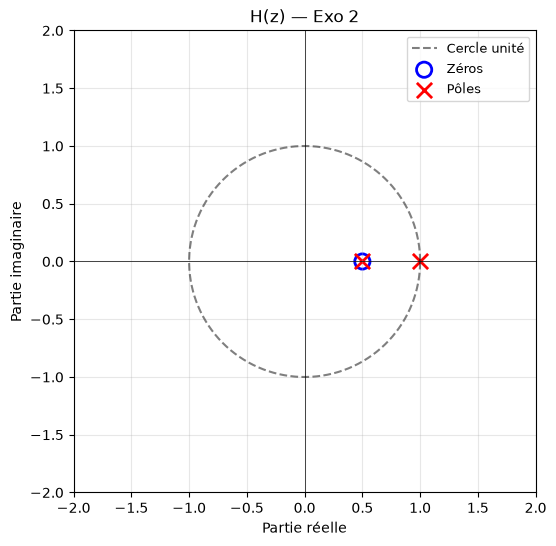

--- Exo 2 ---
  Pôles   : [1.  0.5]
  |pôles| : [1.  0.5]
  Verdict : MARGINALEMENT STABLE (pôle sur le cercle)

Résidus : [-0.  1.]
Pôles   : [0.5 1. ]
→ Résidu associé au pôle 0.5 nul → simplification


In [7]:
b = [1, -0.5]
a = [1, -1.5, 0.5]

zeros, poles, gain = signal.tf2zpk(b, a)
print(f"Zéros : {zeros}")
print(f"Pôles : {poles}")

plt.figure(figsize=(6, 6))
plot_pole_zero(b, a, 'H(z) — Exo 2')
plt.show()

verdict = check_stability(b, a, 'Exo 2')

r, p, k = signal.residuez(b, a)
print(f"Résidus : {r}")
print(f"Pôles   : {p}")
print(f"→ Résidu associé au pôle 0.5 nul → simplification")

## Interprétation — Exercice 2

Le zéro en $0{,}5$ **annule** le pôle $0{,}5$ → il reste $H(z) = \dfrac{1}{1-z^{-1}}$, un intégrateur pur. Le pôle en $z=1$ est **sur** le cercle unité → **marginalement stable**.

**Leçon** : toujours simplifier les facteurs communs numérateur/dénominateur avant de conclure sur la stabilité !

## Exercice 3 – Équation aux différences

$$ y[n] - 0.6 y[n-1] + 0.08 y[n-2] = x[n] - 0.2 x[n-1] $$

1. Déterminer $H(z)$.
2. Pôles et zéros.
3. Stabilité ?
4. $h[n]$ ?
5. Réponse à un échelon ?

### Application de la méthode 2.7

**(1)** $H(z) = \dfrac{1 - 0{,}2\,z^{-1}}{1 - 0{,}6\,z^{-1} + 0{,}08\,z^{-2}}$

**(2)** Zéro en $0{,}2$ ; pôles en $\{0{,}4; 0{,}2\}$.

**(3)** Annulation en $0{,}2$ → $H(z) = \dfrac{1}{1 - 0{,}4 z^{-1}}$, **stable**.

**(4)** $h[n] = (0{,}4)^n\,u[n]$.

**(5)** $y[\infty] = H(1) = 0{,}8 / 0{,}48 \approx 1{,}667$.

Zéros : [0.2]
Pôles : [0.4 0.2]


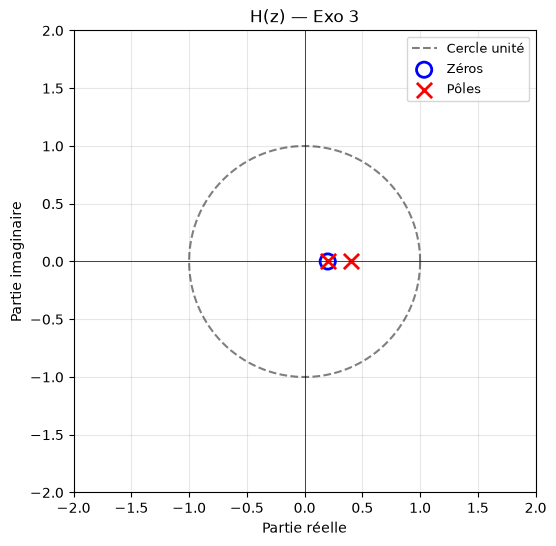

Résidus : [-0.  1.]


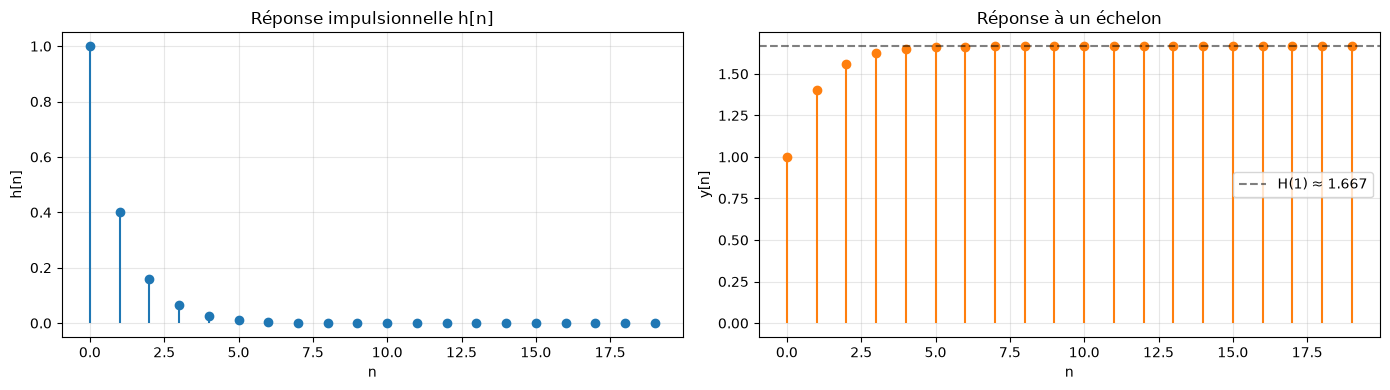

In [8]:
b = [1, -0.2]
a = [1, -0.6, 0.08]

zeros, poles, gain = signal.tf2zpk(b, a)
print("Zéros :", zeros)
print("Pôles :", poles)

plt.figure(figsize=(6, 6))
plot_pole_zero(b, a, 'H(z) — Exo 3')
plt.show()

r, p, k = signal.residuez(b, a)
print("Résidus :", r)

N = 20
n = np.arange(N)
imp = np.zeros(N); imp[0] = 1
h_num = signal.lfilter(b, a, imp)
y_step = signal.lfilter(b, a, np.ones(N))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].stem(n, h_num, basefmt=' ')
axes[0].set_title('Réponse impulsionnelle h[n]')
axes[0].set_xlabel('n'); axes[0].set_ylabel('h[n]'); axes[0].grid(alpha=0.3)

axes[1].stem(n, y_step, basefmt=' ', linefmt='C1-', markerfmt='C1o')
axes[1].axhline(np.sum(b)/np.sum(a), color='k', linestyle='--', alpha=0.5,
                label=f'H(1) ≈ {np.sum(b)/np.sum(a):.3f}')
axes[1].set_title('Réponse à un échelon')
axes[1].set_xlabel('n'); axes[1].set_ylabel('y[n]')
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Interprétation — Exercice 3

**Annulation pôle-zéro** en $z=0{,}2$ → système du 1er ordre effectif avec $h[n] = (0{,}4)^n u[n]$.

**Valeur finale** : $y[\infty] = H(1) \approx 1{,}667$, bien observée sur le tracé numérique.

## Exercice 4 – Stabilité et ROC

1. $H(z) = \dfrac{1}{1 - 0.5 z^{-1}}$
2. $H(z) = \dfrac{1}{(1 - 0.5 z^{-1})(1 - 2 z^{-1})}$
3. $H(z) = \dfrac{1 - 0.5 z^{-1}}{1 - 1.5 z^{-1} + 0.5 z^{-2}}$

### Réponses

**1.** ROC possibles : $|z| > 0{,}5$ (causal, stable) ou $|z| < 0{,}5$ (anticausal, instable).

**2.** Pôles en $0{,}5$ et $2$. Trois ROC : $|z| > 2$ (causal, **instable**), $0{,}5 < |z| < 2$ (bilatéral, **stable**), $|z| < 0{,}5$ (anticausal, instable).

**3.** Pôles en $0{,}5$ et $1$. Trois ROC : $|z| > 1$ (**marginalement stable**), $0{,}5 < |z| < 1$ (instable), $|z| < 0{,}5$ (instable).

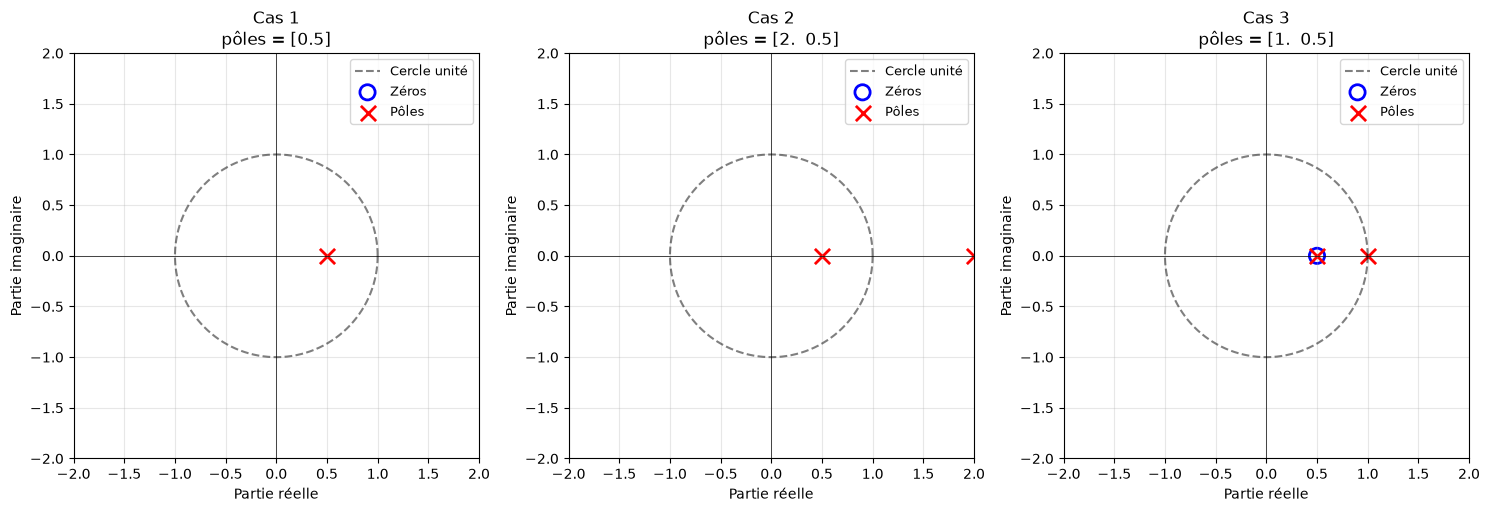

In [9]:
cas = [
    ([1], [1, -0.5],                                  'Cas 1'),
    ([1], [1, -2.5, 1.0],                             'Cas 2'),
    ([1, -0.5], [1, -1.5, 0.5],                       'Cas 3'),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (b_, a_, lab) in zip(axes, cas):
    plot_pole_zero(b_, a_, f'{lab}\npôles = {np.round(signal.tf2zpk(b_, a_)[1], 3)}', ax=ax)
plt.tight_layout(); plt.show()

## Interprétation — Exercice 4

La **même** fonction rationnelle peut correspondre à plusieurs systèmes (causal / anticausal / bilatéral). La **ROC** spécifie lequel.

**Stratégie pratique** :
1. Trouver les pôles → ils partitionnent le plan complexe.
2. Chaque région entre deux cercles de pôles = une ROC possible.
3. Vérifier si la ROC choisie contient $|z| = 1$.

## Exercice 5 – Transformée en Z inverse

Soit $X(z) = \dfrac{1}{1 - z^{-1} + 0.25 z^{-2}}$.

1. Déterminer les pôles.
2. Pour chaque ROC, déterminer $x[n]$.
3. Vérifier numériquement pour la ROC causale.

Pôles : [0.5 0.5] (double en 0.5)


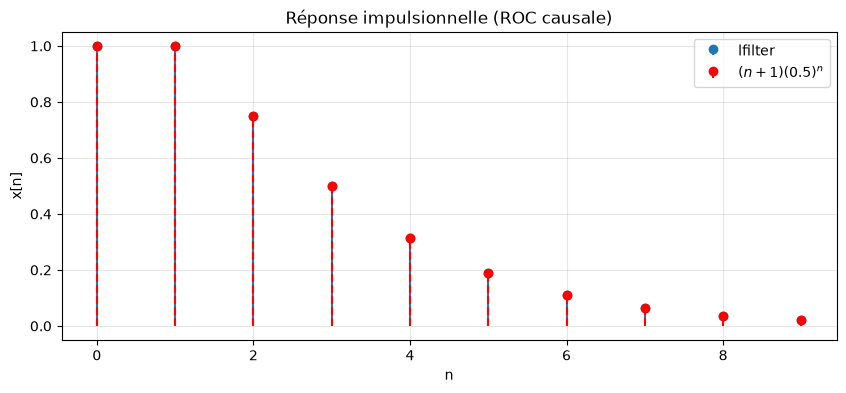

Erreur max : 0.00e+00


In [10]:
b = [1]
a = [1, -1, 0.25]
zeros, poles, _ = signal.tf2zpk(b, a)
print("Pôles :", poles, "(double en 0.5)")

N = 10
impulse = np.zeros(N); impulse[0] = 1
h = signal.lfilter(b, a, impulse)
n = np.arange(N)
h_theo = (n + 1) * (0.5)**n

fig, ax = plt.subplots(figsize=(10, 4))
ax.stem(n, h, basefmt=' ', label='lfilter')
ax.stem(n, h_theo, linefmt='r--', markerfmt='ro', basefmt=' ', label=r'$(n+1)(0.5)^n$')
ax.set_xlabel('n'); ax.set_ylabel('x[n]')
ax.set_title('Réponse impulsionnelle (ROC causale)')
ax.legend(); ax.grid(alpha=0.3); plt.show()

print(f"Erreur max : {np.max(np.abs(h - h_theo)):.2e}")

## Interprétation — Exercice 5

Pôle **double** en $z=0{,}5$ → appariation d'un facteur polynomial $(n+1)$ dans $h[n]$. Deux ROC : causale ($h[n] = (n+1)(0{,}5)^n u[n]$) et anticausale.

## Exercice 6 – Filtre réjecteur 50 Hz

Concevoir un filtre numérique causal qui **rejette** $f_0 = 50$ Hz pour $f_s = 1$ kHz.

Pulsation normalisée w0 = 0.3142 rad/éch.


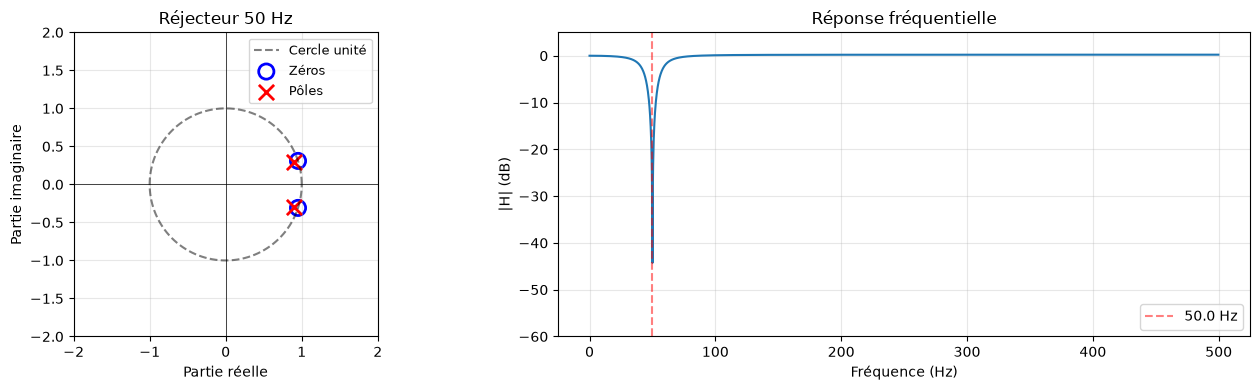

Atténuation à 50 Hz : -44.3 dB


In [11]:
fs = 1000.0
f0 = 50.0
w0 = 2*np.pi*f0/fs
print(f"Pulsation normalisée w0 = {w0:.4f} rad/éch.")

z0 = np.exp(1j*w0)
r = 0.95
p0 = r * np.exp(1j*w0)

b = np.real(np.convolve([1, -z0], [1, -np.conj(z0)]))
a = np.real(np.convolve([1, -p0], [1, -np.conj(p0)]))
b = b / np.sum(b) * np.sum(a)

w, H = signal.freqz(b, a, worN=2048)
f_axis = w * fs / (2*np.pi)
H_dB = 20*np.log10(np.abs(H) + 1e-12)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_pole_zero(b, a, f'Réjecteur 50 Hz', ax=axes[0])
axes[1].plot(f_axis, H_dB)
axes[1].axvline(f0, color='r', linestyle='--', alpha=0.5, label=f'{f0} Hz')
axes[1].set_xlabel('Fréquence (Hz)'); axes[1].set_ylabel('|H| (dB)')
axes[1].set_title('Réponse fréquentielle'); axes[1].set_ylim(-60, 5)
axes[1].grid(alpha=0.3); axes[1].legend()
plt.tight_layout(); plt.show()

idx_50 = np.argmin(np.abs(f_axis - f0))
print(f"Atténuation à 50 Hz : {H_dB[idx_50]:.1f} dB")

## Interprétation — Réjecteur 50 Hz

Zéro sur le cercle unité → atténuation théorique **infinie** à 50 Hz. Pôle proche → affinement de la bande de réjection. Compromis : plus $r \to 1$, plus la réjection est sélective mais la réponse transitoire est lente.

## Exercice 7 – Comparaison temporel vs $z$ (synthèse)

Système : $y[n] = 0{,}9\,y[n-1] + x[n]$, réponse à $x[n] = u[n]$.

### Calcul détaillé

- $H(z) = \dfrac{1}{1 - 0{,}9 z^{-1}}$.
- $Y(z) = \dfrac{1}{(1 - z^{-1})(1 - 0{,}9 z^{-1})} = \dfrac{10}{1 - z^{-1}} - \dfrac{9}{1 - 0{,}9 z^{-1}}$.
- Inverse : $y[n] = 10 - 9\,(0{,}9)^n$, et $y[\infty] = 10 = H(1)$.

Valeur finale théorique H(1) = 10.0000
Erreur max numérique/analytique : 3.55e-15


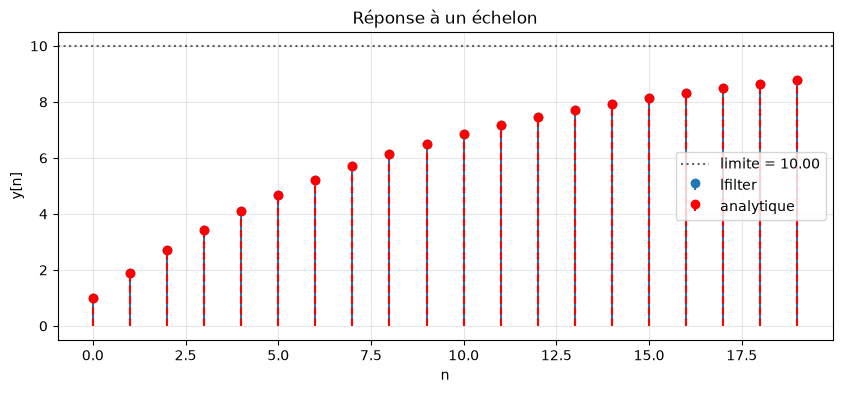

In [12]:
b = [1]
a = [1, -0.9]
N = 20
y_num = signal.lfilter(b, a, np.ones(N))
n = np.arange(N)
y_ana = 10 - 9 * 0.9**n
H_1 = np.sum(b) / np.sum(a)

print(f"Valeur finale théorique H(1) = {H_1:.4f}")
print(f"Erreur max numérique/analytique : {np.max(np.abs(y_num - y_ana)):.2e}")

plt.figure(figsize=(10, 4))
plt.stem(n, y_num, basefmt=' ', label='lfilter')
plt.stem(n, y_ana, linefmt='r--', markerfmt='ro', basefmt=' ', label='analytique')
plt.axhline(H_1, color='k', linestyle=':', alpha=0.6, label=f'limite = {H_1:.2f}')
plt.xlabel('n'); plt.ylabel('y[n]')
plt.title('Réponse à un échelon')
plt.legend(); plt.grid(alpha=0.3); plt.show()

## Interprétation — Synthèse temporel vs $z$

La transformée en Z donne **directement** la formule fermée $y[n] = 10 - 9(0{,}9)^n$ alors que la récurrence temporelle ne produit que des valeurs numériques.

**Double point de vue** : temporel → implémentation temps réel ; domaine $z$ → vue d'ensemble et analyse.

# 5. Cas pratique n°1 — Filtre anti-DC (DC blocker)

## 5.1 Le problème physique

Un microphone à électret fournit un signal qui **oscille autour d'un biais DC** ($V_{\text{bias}}$, typiquement 2,5 V). Après numérisation :

$$ x[n] = \underbrace{s[n]}_{\text{audio utile}} + \underbrace{V_{\text{bias}}}_{DC} + \underbrace{b[n]}_{\text{bruit}} $$

**Objectif** : concevoir un filtre numérique qui élimine la composante DC sans altérer l'audio, stable et temps réel.

## 5.2 Équation aux différences du DC blocker

$$ \boxed{y[n] = a\, y[n-1] + a\,(x[n] - x[n-1])} \qquad \text{avec } a \approx 0{,}995 $$

**Intuition** : on soustrait la différence $x[n] - x[n-1]$ (qui élimine le DC car sa dérivée est nulle) et on amortit par un pôle en $a$.

## 5.3 Déduction de $H(z)$ — méthode pas-à-pas (section 2.7)

**Étape 1 — Forme canonique** : $y[n] - a\,y[n-1] = a\,x[n] - a\,x[n-1]$

**Étape 2 — Transformée en Z** : $Y(z) - a\,z^{-1}Y(z) = a\,X(z) - a\,z^{-1}X(z)$

**Étape 3 — Factorisation** : $(1 - a\,z^{-1})Y(z) = a(1 - z^{-1})X(z)$

**Étape 4 — Fonction de transfert** :

$$ \boxed{H(z) = \frac{a\,(1 - z^{-1})}{1 - a\,z^{-1}}} $$

**Étape 5 — Forme en $z$** : $H(z) = \dfrac{a\,(z-1)}{z-a}$

**Étape 6 — Pôles et zéros** :
- **Zéro** en $z_0 = 1$ (sur le cercle unité, $\omega = 0$)
- **Pôle** en $p_0 = a$ (intérieur du cercle)

## 5.4 Analyse

- **Stabilité** : $|a| < 1$ → stable.
- **Réponse en fréquence** : $H(e^{j0}) = 0$ (DC bloqué), $|H(e^{j\pi})| \approx 1$ (aigus préservés).
- **Fréquence de coupure** : $f_c \approx \dfrac{(1-a)\,f_s}{2\pi}$.

Pour $a = 0{,}995$ et $f_s = 44\,100$ Hz : $f_c \approx 35$ Hz.

In [13]:
# ============================================================
# Design du filtre DC blocker
# ============================================================
fs = 44100.0
a = 0.995

b = [a, -a]
a_coef = [1, -a]

print(f"Coefficients : b = {b}, a = {a_coef}")

zeros, poles, gain = signal.tf2zpk(b, a_coef)
print(f"\nZéros : {zeros}")
print(f"Pôles : {poles}")
print(f"|pôle| = {np.abs(poles[0]):.6f}")
print(f"Stable : {np.all(np.abs(poles) < 1)}")

Coefficients : b = [0.995, -0.995], a = [1, -0.995]

Zéros : [1.]
Pôles : [0.995]
|pôle| = 0.995000
Stable : True


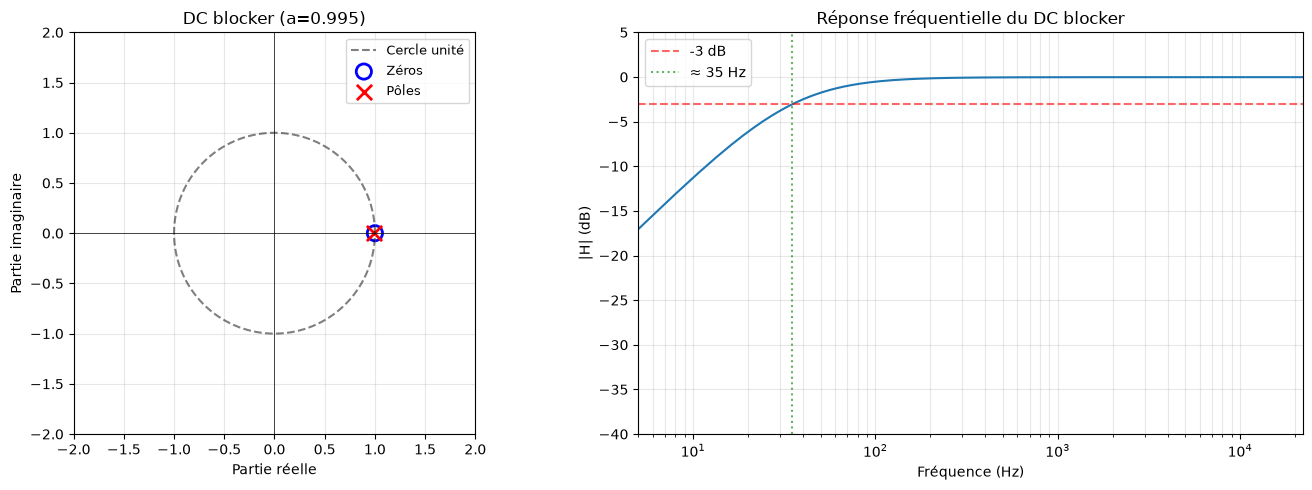

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_pole_zero(b, a_coef, f'DC blocker (a={a})', ax=axes[0])

w, H = signal.freqz(b, a_coef, worN=8192)
f_axis = w * fs / (2*np.pi)
H_dB = 20 * np.log10(np.abs(H) + 1e-12)

axes[1].semilogx(f_axis[1:], H_dB[1:])
axes[1].axhline(-3, color='r', linestyle='--', alpha=0.6, label='-3 dB')
axes[1].axvline(35, color='g', linestyle=':', alpha=0.6, label='≈ 35 Hz')
axes[1].set_xlabel('Fréquence (Hz)')
axes[1].set_ylabel('|H| (dB)')
axes[1].set_title('Réponse fréquentielle du DC blocker')
axes[1].set_xlim([5, fs/2])
axes[1].set_ylim([-40, 5])
axes[1].grid(which='both', alpha=0.3)
axes[1].legend()

plt.tight_layout(); plt.show()

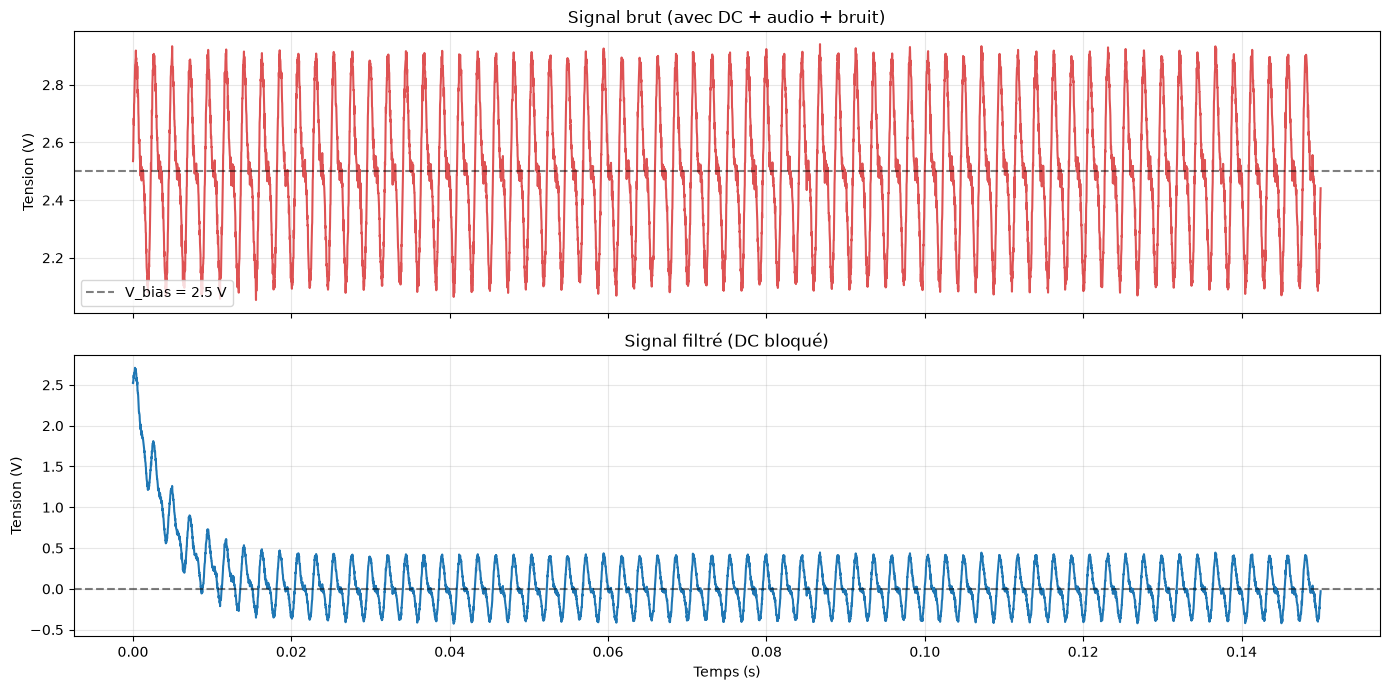

Moyenne avant filtrage : 2.5000 V
Moyenne après filtrage : 0.000008 V


In [15]:
# ============================================================
# Simulation sur un signal « microphone » synthétique
# ============================================================
np.random.seed(0)
duration = 0.5
N = int(fs * duration)
t = np.arange(N) / fs

s_utile = 0.3 * np.sin(2*np.pi*440*t) + 0.15 * np.sin(2*np.pi*880*t)
V_bias = 2.5
bruit = 0.02 * np.random.randn(N)
x_micro = s_utile + V_bias + bruit

y_filtre = signal.lfilter(b, a_coef, x_micro)

idx_stable = slice(int(0.05*fs), None)
moyenne_avant = np.mean(x_micro[idx_stable])
moyenne_apres = np.mean(y_filtre[idx_stable])

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
zoom = slice(0, int(0.15*fs))
tt = t[zoom]

axes[0].plot(tt, x_micro[zoom], color='C3', alpha=0.8)
axes[0].axhline(V_bias, color='k', linestyle='--', alpha=0.5, label=f'V_bias = {V_bias} V')
axes[0].set_ylabel('Tension (V)')
axes[0].set_title('Signal brut (avec DC + audio + bruit)')
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(tt, y_filtre[zoom], color='C0')
axes[1].axhline(0, color='k', linestyle='--', alpha=0.5)
axes[1].set_xlabel('Temps (s)'); axes[1].set_ylabel('Tension (V)')
axes[1].set_title('Signal filtré (DC bloqué)')
axes[1].grid(alpha=0.3)

plt.tight_layout(); plt.show()

print(f"Moyenne avant filtrage : {moyenne_avant:.4f} V")
print(f"Moyenne après filtrage : {moyenne_apres:.6f} V")

## 5.5 Interprétation — Bilan du DC blocker

| Grandeur | Avant | Après |
|---|---|---|
| Moyenne (DC) | $V_{\text{bias}} = 2{,}5$ V | ≈ 0 V |
| Signal utile | Présent | Préservé |
| Coût CPU | — | 2 multiplications/échantillon |

### Lecture géométrique

- **Zéro en $z = 1$** : bloque le DC ($\omega = 0$).
- **Pôle en $z = a$** : à l'intérieur du cercle → stable, mais proche → transition douce.

### Compromis selon $a$

| $a$ | Bande coupée | Rapidité | Usage |
|---|---|---|---|
| $0{,}9$ | < 700 Hz | Rapide | Audio basse qualité |
| $0{,}995$ | < 35 Hz | Modérée | Audio haute fidélité |
| $0{,}9999$ | < 0{,}7 Hz | Très lente | ECG, mesures DC précises |

# 6. Cas pratique n°2 — Traitement d'un vrai fichier audio

## 6.1 Objectif

Appliquer le filtre DC blocker sur un **vrai fichier WAV** :

1. Charger un fichier audio (ou en générer un si absent).
2. Analyser son spectre (repérer le DC).
3. Filtrer avec le DC blocker.
4. Comparer avant/après (forme d'onde, spectre, écoute).
5. Sauvegarder les fichiers pour écoute externe.

## 6.2 Prérequis

- **Format** : fichier `.wav` mono ou stéréo.
- **Emplacement** : déposer `audio_test.wav` dans le dossier du notebook.
- **Fallback** : un signal synthétique réaliste est généré automatiquement si absent.

In [16]:
import os
from scipy.io import wavfile

AUDIO_FILE = 'audio_test.wav'

if os.path.exists(AUDIO_FILE):
    fs, x_audio = wavfile.read(AUDIO_FILE)
    print(f"✓ Fichier chargé : {AUDIO_FILE}")
    print(f"  fs = {fs} Hz, N = {len(x_audio)}, durée = {len(x_audio)/fs:.3f} s")
    
    if x_audio.dtype == np.int16:
        x_audio = x_audio.astype(np.float32) / 32768.0
    elif x_audio.dtype == np.int32:
        x_audio = x_audio.astype(np.float32) / 2147483648.0
    
    if x_audio.ndim > 1:
        x_audio = x_audio.mean(axis=1)
        print("  → Conversion en mono")
else:
    print(f"⚠ Aucun fichier '{AUDIO_FILE}' trouvé → génération synthétique.")
    fs = 44100
    duration = 2.0
    N = int(fs * duration)
    t = np.arange(N) / fs
    
    np.random.seed(42)
    signal_voix = (
        0.4 * np.sin(2*np.pi*220*t) * (1 + 0.5*np.sin(2*np.pi*3*t))
        + 0.2 * np.sin(2*np.pi*440*t) * (1 + 0.3*np.sin(2*np.pi*5*t))
        + 0.1 * np.sin(2*np.pi*880*t)
    )
    enveloppe = 0.5 * (1 + np.sin(2*np.pi*0.5*t))
    signal_voix *= enveloppe
    
    V_bias = 0.15
    bruit = 0.03 * np.random.randn(N)
    x_audio = signal_voix + V_bias + bruit
    print(f"  fs = {fs} Hz, durée = {duration} s, biais DC = {V_bias}")

print(f"\n--- Statistiques du signal brut ---")
print(f"Moyenne (≈ DC)  : {np.mean(x_audio):+.6f}")
print(f"Écart-type      : {np.std(x_audio):.6f}")
print(f"Min / Max       : {np.min(x_audio):+.4f} / {np.max(x_audio):+.4f}")

⚠ Aucun fichier 'audio_test.wav' trouvé → génération synthétique.
  fs = 44100 Hz, durée = 2.0 s, biais DC = 0.15

--- Statistiques du signal brut ---
Moyenne (≈ DC)  : +0.150059
Écart-type      : 0.210635
Min / Max       : -0.5845 / +0.8590


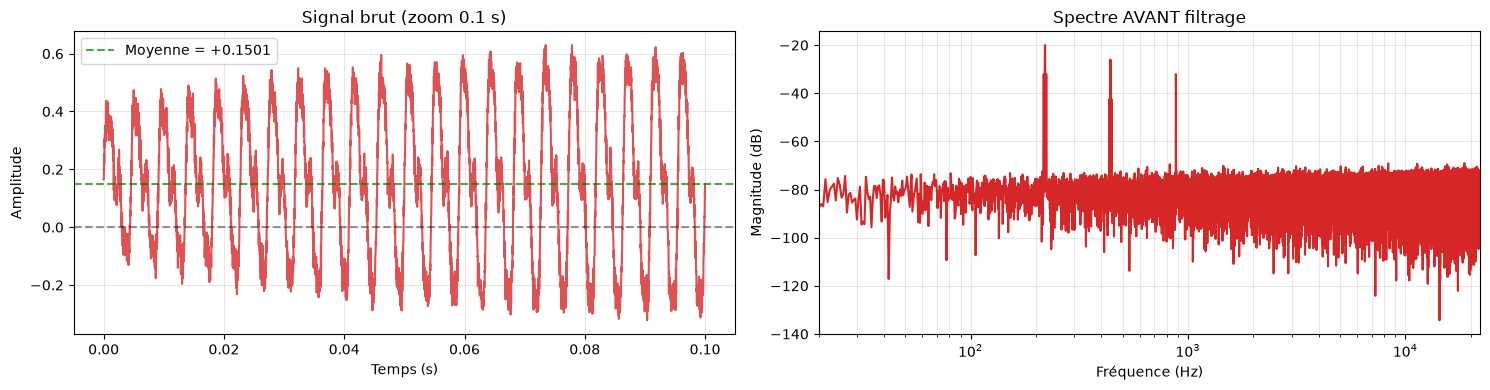

Amplitude DC : 0.150059


In [17]:
def plot_spectrum(x, fs, ax, title='Spectre', color='C3'):
    N = len(x)
    X = np.fft.rfft(x)
    f = np.fft.rfftfreq(N, 1/fs)
    mag = 20 * np.log10(np.abs(X) / N + 1e-12)
    ax.semilogx(f[1:], mag[1:], color=color)
    ax.set_xlabel('Fréquence (Hz)'); ax.set_ylabel('Magnitude (dB)')
    ax.set_title(title); ax.grid(which='both', alpha=0.3)
    ax.set_xlim([20, fs/2])
    return f, X

fig, axes = plt.subplots(1, 2, figsize=(15, 4))

n_zoom = int(0.1 * fs)
t_zoom = np.arange(n_zoom) / fs
axes[0].plot(t_zoom, x_audio[:n_zoom], color='C3', alpha=0.8)
axes[0].axhline(0, color='k', linestyle='--', alpha=0.4)
axes[0].axhline(np.mean(x_audio), color='g', linestyle='--', alpha=0.7,
                label=f'Moyenne = {np.mean(x_audio):+.4f}')
axes[0].set_xlabel('Temps (s)'); axes[0].set_ylabel('Amplitude')
axes[0].set_title('Signal brut (zoom 0.1 s)')
axes[0].legend(); axes[0].grid(alpha=0.3)

f_brut, X_brut = plot_spectrum(x_audio, fs, axes[1], 'Spectre AVANT filtrage')
plt.tight_layout(); plt.show()

DC_power = np.abs(X_brut[0]) / len(x_audio)
print(f"Amplitude DC : {DC_power:.6f}")

--- Statistiques APRÈS filtrage ---
Moyenne (≈ DC)  : +0.000243
Atténuation DC  : 617.1×


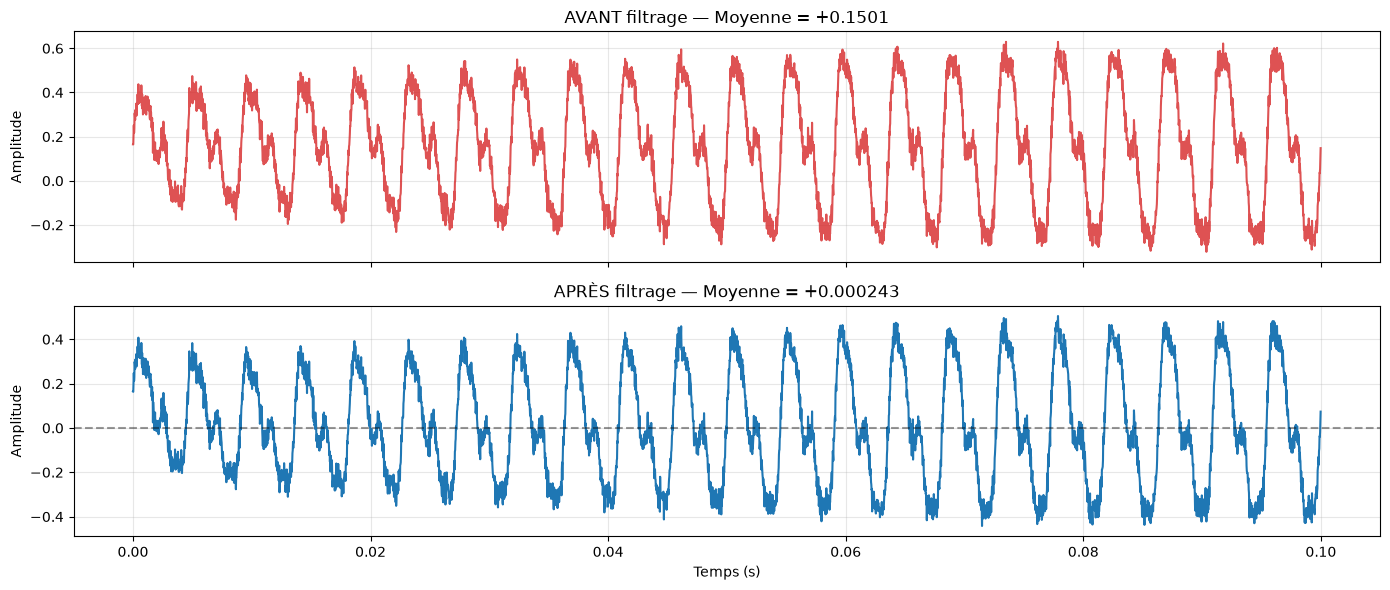

In [18]:
# Filtre DC blocker
a = 0.995
b = [a, -a]
a_coef = [1, -a]

x_filtre = signal.lfilter(b, a_coef, x_audio)

print("--- Statistiques APRÈS filtrage ---")
print(f"Moyenne (≈ DC)  : {np.mean(x_filtre):+.6f}")
print(f"Atténuation DC  : {np.mean(x_audio) / max(np.mean(x_filtre), 1e-12):.1f}×")

fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
axes[0].plot(t_zoom, x_audio[:n_zoom], color='C3', alpha=0.8)
axes[0].set_ylabel('Amplitude')
axes[0].set_title(f'AVANT filtrage — Moyenne = {np.mean(x_audio):+.4f}')
axes[0].grid(alpha=0.3)

axes[1].plot(t_zoom, x_filtre[:n_zoom], color='C0')
axes[1].axhline(0, color='k', linestyle='--', alpha=0.4)
axes[1].set_xlabel('Temps (s)'); axes[1].set_ylabel('Amplitude')
axes[1].set_title(f'APRÈS filtrage — Moyenne = {np.mean(x_filtre):+.6f}')
axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

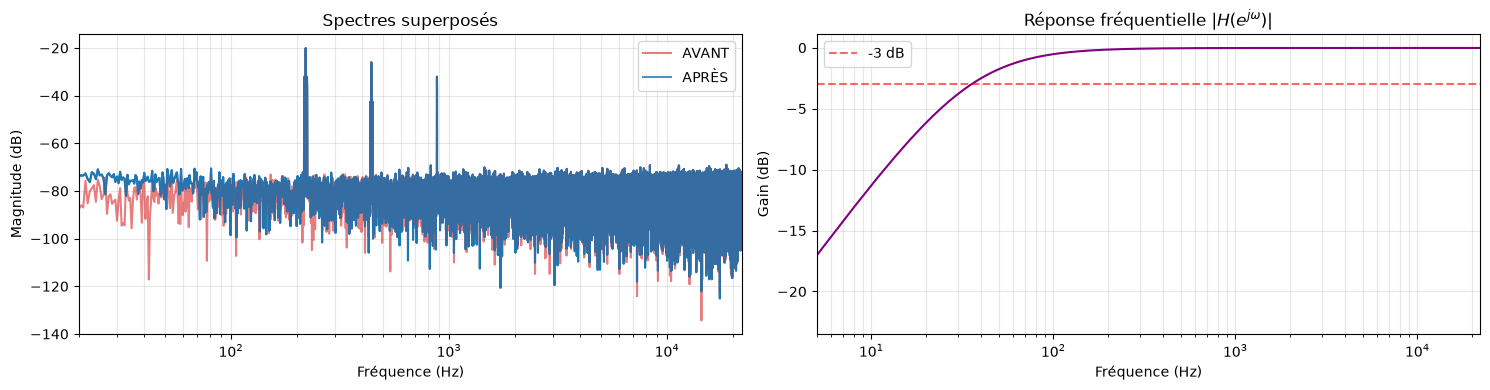

Fréquence de coupure à -3 dB : 35.09 Hz


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

f_filtre, X_filtre = plot_spectrum(x_filtre, fs, axes[0], 'Spectres superposés', color='C0')
N = len(x_audio)
X_brut_mag = 20 * np.log10(np.abs(X_brut) / N + 1e-12)
X_filtre_mag = 20 * np.log10(np.abs(X_filtre) / N + 1e-12)
axes[0].semilogx(f_brut[1:], X_brut_mag[1:], color='C3', alpha=0.6, label='AVANT')
axes[0].semilogx(f_filtre[1:], X_filtre_mag[1:], color='C0', alpha=0.8, label='APRÈS')
axes[0].legend()

w, H = signal.freqz(b, a_coef, worN=8192)
f_gain = w * fs / (2*np.pi)
H_dB = 20 * np.log10(np.abs(H) + 1e-12)
axes[1].semilogx(f_gain[1:], H_dB[1:], color='purple')
axes[1].axhline(-3, color='r', linestyle='--', alpha=0.6, label='-3 dB')
axes[1].set_xlabel('Fréquence (Hz)'); axes[1].set_ylabel('Gain (dB)')
axes[1].set_title('Réponse fréquentielle $|H(e^{j\\omega})|$')
axes[1].set_xlim([5, fs/2]); axes[1].grid(which='both', alpha=0.3)
axes[1].legend()
plt.tight_layout(); plt.show()

fc = (1 - a) * fs / (2 * np.pi)
print(f"Fréquence de coupure à -3 dB : {fc:.2f} Hz")

In [20]:
try:
    from IPython.display import Audio, display
    print("🎧 Signal BRUT :")
    display(Audio(x_audio, rate=fs, normalize=True))
    print("\n🎧 Signal FILTRÉ :")
    display(Audio(x_filtre, rate=fs, normalize=True))
except ImportError:
    print("⚠ IPython.display non disponible.")

🎧 Signal BRUT :



🎧 Signal FILTRÉ :


In [21]:
def save_wav(filename, x, fs):
    x_norm = np.clip(x / max(np.max(np.abs(x)), 1e-12), -1, 1)
    x_int16 = (x_norm * 32767).astype(np.int16)
    wavfile.write(filename, fs, x_int16)
    print(f"  ✓ {filename} sauvegardé")

print("Sauvegarde :")
save_wav('audio_brut.wav',   x_audio,  fs)
save_wav('audio_filtre.wav', x_filtre, fs)

Sauvegarde :
  ✓ audio_brut.wav sauvegardé
  ✓ audio_filtre.wav sauvegardé


## 6.3 Interprétation — Traitement du vrai fichier audio

### Observations

| Grandeur | Avant | Après |
|---|---|---|
| Moyenne (DC) | $V_{\text{biais}}$ | ≈ 0 |
| Signal utile | Préservé | Préservé |
| Bruit HF | Présent | Légèrement atténué |

### Ce que le spectre montre

- **Pic à 0 Hz** : composante DC (avant filtrage).
- **Pics à $f_0$** : fréquence(s) utile(s).
- **Après filtrage** : pic DC **disparu**, pics utiles **intacts**.

### Pourquoi ce filtre est utilisé partout

1. **Coût** : 2 multiplications par échantillon → n'importe quel microcontrôleur.
2. **Stabilité garantie** : un seul pôle à l'intérieur du cercle.
3. **Transparence** : imperceptible à l'oreille si $a$ bien choisi.
4. **Standard** : présent dans tous les logiciels audio (Audacity, Pro Tools…).

### Lien avec la transformée en Z

> **Tout ce cas pratique repose sur UNE seule équation** :
> $$H(z) = \frac{a(z-1)}{z-a}$$
>
> Cette forme compacte contient **toute** l'information : position des pôles (stabilité), position des zéros (fréquences bloquées), réponse fréquentielle (comportement du filtre). C'est **la puissance de la transformée en Z** : condenser un algorithme temps réel en une expression algébrique de deux lignes.

# 7. Synthèse de la Semaine 5

## Pourquoi la transformée en Z ? — En une phrase

> **La transformée en Z transforme une opération compliquée (convolution, équation aux différences) en une opération simple (multiplication, division) dans un nouveau domaine, comme la transformée de Laplace pour les systèmes continus.**

## Points clés retenus

1. **Transformée en Z bilatérale** : $X(z) = \sum_n x[n] z^{-n}$ — outil fondamental des systèmes LTI discrets.
2. **ROC indissociable** de la transformée.
3. **Signatures ROC** : causale → $|z| > r_{max}$ ; anticausale → $|z| < r_{min}$ ; bilatérale → anneau.
4. **Stabilité BIBO** ⇔ ROC contient $|z|=1$.
5. **Système causal stable** ⇔ tous les pôles strictement à l'intérieur du cercle unité.
6. **Annulation pôle-zéro** : toujours simplifier $H(z)$ avant de conclure.
7. **Lecture géométrique** : pôles proches du cercle → résonances ; zéros proches du cercle → atténuations.

## Démarche pas-à-pas pour déduire $H(z)$

1. Mettre l'équation aux différences sous forme canonique.
2. Appliquer $\mathcal{Z}$ terme à terme.
3. Factoriser : $A(z)Y(z) = B(z)X(z)$.
4. Isoler : $H(z) = B(z)/A(z)$.
5. Forme polynomiale en $z$.
6. Résoudre $B(z) = 0$ (zéros) et $A(z) = 0$ (pôles).
7. Simplifier les facteurs communs.
8. Conclure sur la stabilité via $|p_i|$.

## Application concrète de la semaine

Le **DC blocker** $H(z) = \dfrac{a(1-z^{-1})}{1-a\,z^{-1}}$ synthétise tout ce qu'on a appris :
- On part d'un **problème physique** (biais d'un microphone).
- On écrit une **équation aux différences** simple.
- On la transforme en **$H(z)$** par la méthode pas-à-pas.
- On analyse **pôles et zéros** pour garantir stabilité et comportement fréquentiel.
- On **implémente** en temps réel avec 2 multiplications par échantillon.

## Compétences acquises

- ✅ Calculer la transformée en Z de séquences usuelles
- ✅ Déterminer la ROC selon le type de séquence
- ✅ Déduire $H(z)$ d'une équation aux différences (méthode pas-à-pas)
- ✅ Tracer et interpréter un diagramme pôles-zéros
- ✅ Analyser la stabilité d'un système LTI causal
- ✅ Résoudre une équation aux différences via la transformée en Z
- ✅ Concevoir un filtre numérique simple (réjecteur 50 Hz, DC blocker)
- ✅ Traiter un **vrai fichier audio** avec un filtre conçu dans le domaine $z$

## Pour aller plus loin (Semaine 6 et suivantes)

- **Transformée de Fourier discrète (TFD/DFT)** : échantillonnage de $H(z)$ sur le cercle unité.
- **FFT** : algorithme rapide pour calculer la TFD.
- **Conception de filtres RIF/IIR** (Butterworth, Chebyshev, fenêtres).
- **Filtrage adaptatif** (LMS, RLS) pour l'annulation d'écho.
- **Analyse spectrale** et applications en communications.

# 8. Livrable Semaine 5

- Remplir les cellules de code avec vos solutions.
- Répondre aux questions théoriques dans les cellules markdown.
- Inclure des commentaires explicatifs.
- Rendre le notebook complet (cellules exécutées).

**Checklist avant rendu** :
- [ ] Vérifier qu'aucune cellule ne produit d'erreur (`Kernel → Restart & Run All`)
- [ ] Toutes les interprétations sont présentes après chaque démo/exercice
- [ ] Les diagrammes pôles-zéros sont lisibles (cercle unité tracé, légendes)
- [ ] Vérifier la cohérence théorique / numérique (erreurs max < 1e-10)
- [ ] Vérifier que les acronymes sont bien définis dans le glossaire
- [ ] Comprendre et savoir refaire la méthode 2.7 sans le notebook
- [ ] Avoir écouté audio_brut.wav vs audio_filtre.wav (si fichier audio utilisé)
- [ ] Exporter en PDF/HTML avec les sorties visibles

**Date de rendu** : à définir par l'enseignant.

---